# Utility Consumption Anomaly Tracker — exploratory walkthrough

Companion notebook to the repo's `main.py` pipeline. See the root `README.md` for the
full write-up (dataset credits, methodology, known limitations). This notebook just
walks through the same pipeline interactively, cell by cell.


In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
os.chdir("..")  # so relative paths in src/ (data/raw/...) resolve the same as main.py

import pandas as pd
import matplotlib.pyplot as plt

from src.pipeline import load_interval_series, load_cumulative_series, detect_anomalies, estimate_cost_impact
from src.modeling import derive_wtp_output, derive_stp_treated, validate_detector

pd.set_option("display.max_columns", None)


## 1. Load the real meter data

In [2]:
electricity = load_interval_series("data/raw/electricity_15min.csv")
raw_water, n_resets = load_cumulative_series("data/raw/water_meter_cumulative.csv")

print(f"Electricity: {len(electricity)} days, {electricity.index.min().date()} to {electricity.index.max().date()}")
print(f"Raw water:   {len(raw_water)} days (sparse readings), {n_resets} meter-reset reading(s) excluded")
electricity.describe()


Electricity: 364 days, 2019-01-01 to 2019-12-30
Raw water:   145 days (sparse readings), 25 meter-reset reading(s) excluded


count     364.000000
mean     3657.195742
std       397.514667
min        28.250000
25%      3480.750000
50%      3735.125000
75%      3917.312500
max      4162.000000
Name: value, dtype: float64

## 2. Electricity — anomaly detection on real, continuous daily data

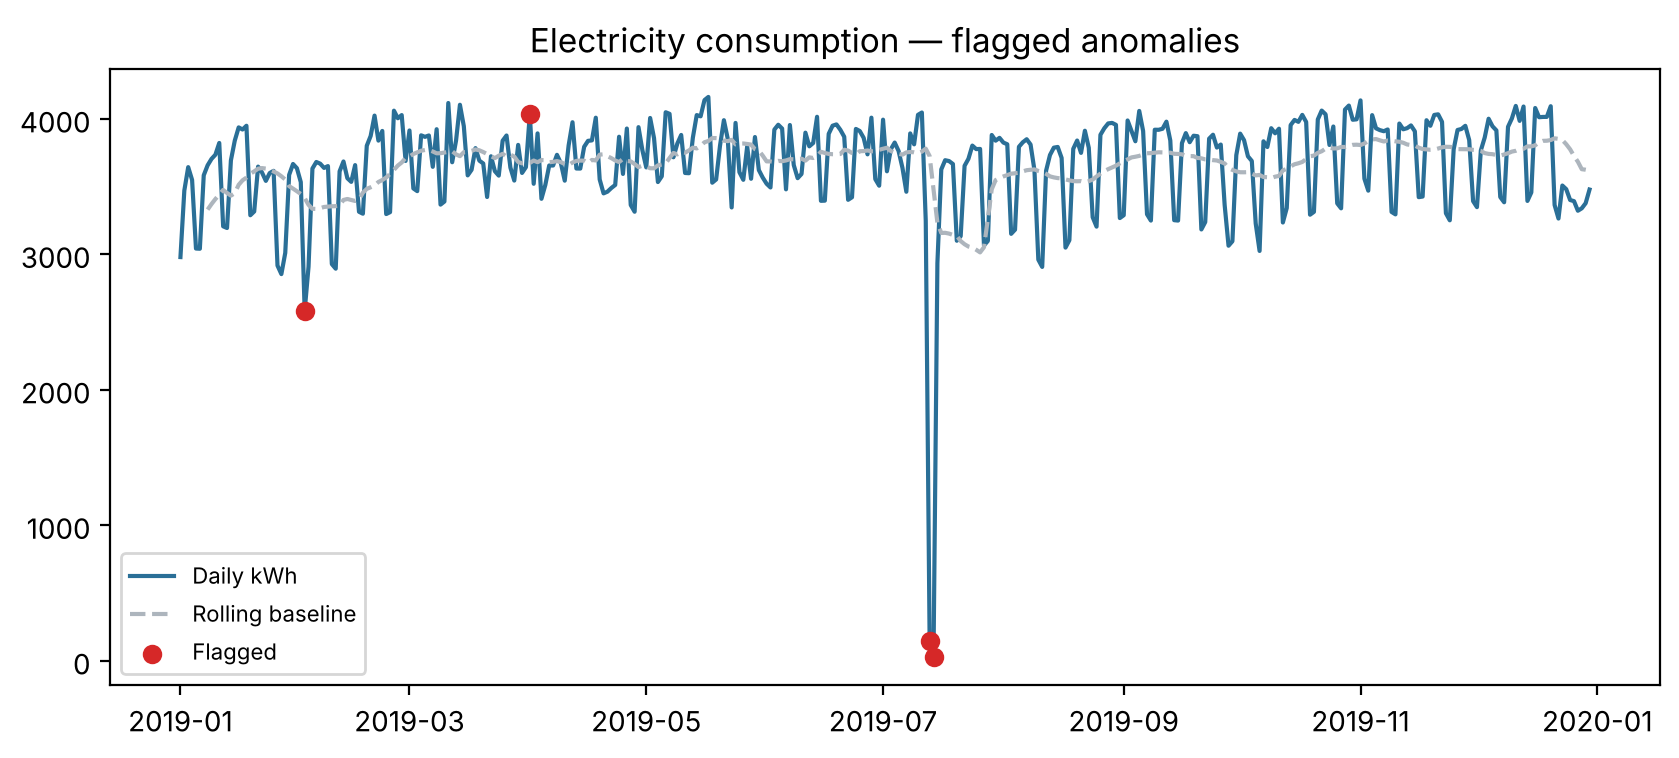

,value,rolling_mean,zscore,direction,severity,estimated_cost_impact
date,,,,,,
2019-02-02,2581.50,3415.964286,-2.993049,drop,moderate,0.0
2019-04-01,4034.25,3674.607143,3.005209,spike,moderate,100.7
2019-07-13,143.00,3725.928571,-15.875174,drop,high,0.0
2019-07-14,28.25,3482.178571,-3.627875,drop,high,0.0


In [3]:
elec_result = detect_anomalies(electricity, window=14, z_threshold=3.0)
elec_result = estimate_cost_impact(elec_result, rate_per_unit=0.28)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(elec_result.index, elec_result["value"], label="Daily kWh", color="#2a6f97")
ax.plot(elec_result.index, elec_result["rolling_mean"], "--", color="#adb5bd", label="Rolling baseline")
flagged = elec_result[elec_result["is_anomaly"]]
ax.scatter(flagged.index, flagged["value"], color="#d62828", zorder=5, label="Flagged")
ax.set_title("Electricity consumption — flagged anomalies")
ax.legend(fontsize=8)
plt.show()

elec_result[elec_result["is_anomaly"]][["value", "rolling_mean", "zscore", "direction", "severity", "estimated_cost_impact"]]


## 3. Raw water + modeled WTP/STP

`wtp_output` and `stp_treated` are **derived** from the real raw-water series (see
`src/modeling.py` for why no real public dataset exists for these) — labeled "(modeled)"
throughout, never presented as measured sensor data.


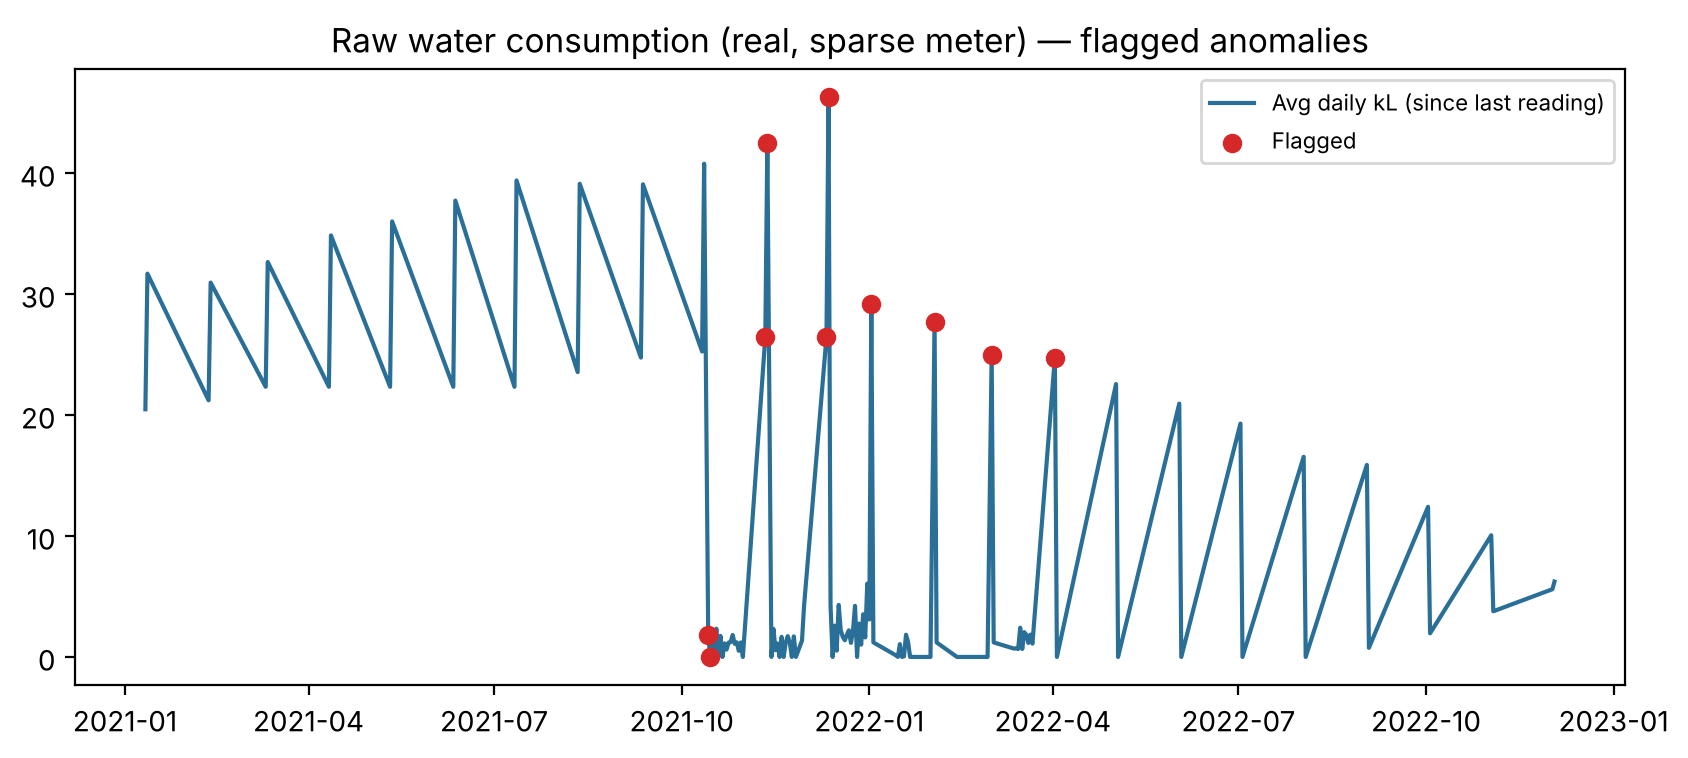

10 of 145 days flagged


In [4]:
wtp_output = derive_wtp_output(raw_water)
stp_treated = derive_stp_treated(raw_water)

water_result = detect_anomalies(raw_water, window=14, z_threshold=3.0, use_log=True)
water_result = estimate_cost_impact(water_result, rate_per_unit=3.50)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(water_result.index, water_result["value"], label="Avg daily kL (since last reading)", color="#2a6f97")
flagged = water_result[water_result["is_anomaly"]]
ax.scatter(flagged.index, flagged["value"], color="#d62828", zorder=5, label="Flagged")
ax.set_title("Raw water consumption (real, sparse meter) — flagged anomalies")
ax.legend(fontsize=8)
plt.show()

print(f"{water_result['is_anomaly'].sum()} of {len(water_result)} days flagged")


## 4. Validating the detector against known, injected anomalies

In [5]:
elec_validation = validate_detector(electricity, lambda s: detect_anomalies(s, window=14, z_threshold=3.0))
water_validation = validate_detector(raw_water, lambda s: detect_anomalies(s, window=14, z_threshold=3.0, use_log=True))

pd.DataFrame([
    {"track": "Electricity", **elec_validation},
    {"track": "Raw water", **water_validation},
])


,track,n_injected,n_flagged_total,true_positives,precision,recall
0,Electricity,12,15,12,0.8,1.00
1,Raw water,12,10,3,0.3,0.25


## 5. Full run

`python main.py` from the repo root runs all four tracks (electricity, raw water, WTP
output, STP treated volume), and writes:

- `outputs/anomaly_report.xlsx` — Summary / Cost-Saving Opportunities / one sheet per metric
- `outputs/charts/*.png` — one trend+anomaly chart per metric
- `outputs/summary.md` — the same numbers in Markdown, regenerated on every run

See the root `README.md` for the latest numbers, dataset credits, and known limitations
(notably: why the water track's precision/recall is lower than electricity's, and why
WTP/STP are modeled rather than measured).
